In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [3]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

print(df.head())
print("Dataset Shape:", df.shape)

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [4]:
features = ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']

X = df[features].copy()

# Handle missing values
X = X.fillna(X.median())

# Normalize data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

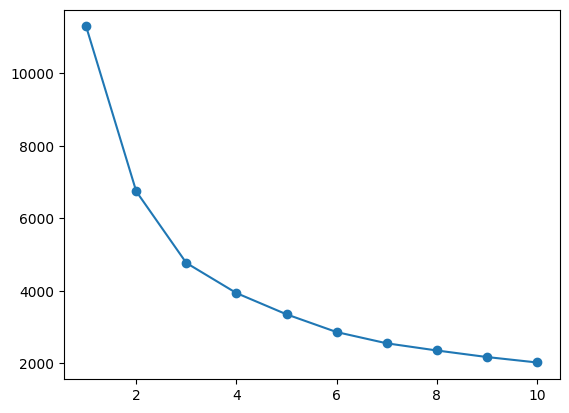

In [7]:
inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k,random_state=42, n_init=10)
    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)

plt.plot(range(1, 11), inertia, marker = 'o')

In [8]:
optimal_k = 3

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print("Cluster Labels:")
print(df['Cluster'].value_counts().sort_index())

print("\nFirst 10 Records:")
print(df[['SALES', 'QUANTITYORDERED', 'Cluster']].head(10))

Cluster Labels:
Cluster
0    975
1    852
2    996
Name: count, dtype: int64

First 10 Records:
     SALES  QUANTITYORDERED  Cluster
0  2871.00               30        2
1  2765.90               34        2
2  3884.34               41        1
3  3746.70               45        1
4  5205.27               49        1
5  3479.76               36        2
6  2497.77               29        2
7  5512.32               48        1
8  2168.54               22        2
9  4708.44               41        1


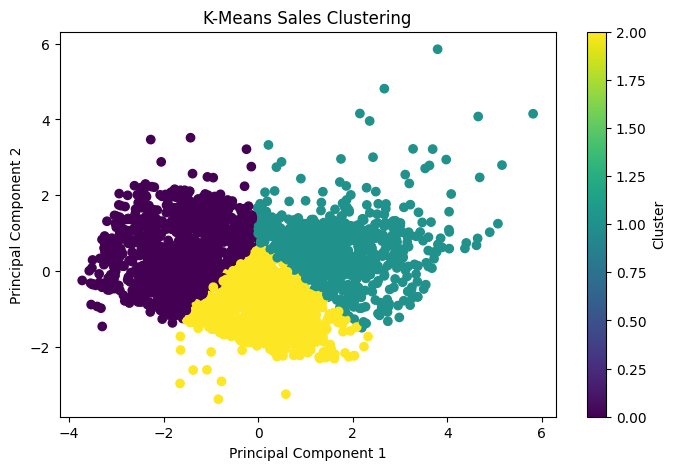

In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df['Cluster'],
    cmap='viridis'
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Sales Clustering")

plt.colorbar(label="Cluster")
plt.show()